# 13 · Machine-learning models

The baselines set the bar: Elo alone scores a development log loss of
0.957. This notebook asks four questions, all answered on the development
seasons (2008/09-2013/14) only:

1. Do tree ensembles (random forest, XGBoost, LightGBM) beat the baselines?
2. Does hyperparameter tuning (Optuna, nested inside each training window)
   help?
3. Does combining models help?
4. Does StatsBomb **event data** improve predictions for Barcelona?

Every run is logged to MLflow (`mlflow.db`, experiment `match-outcome-dev`)
with its parameters, features, overall and per-season metrics and
predictions.

In [1]:
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt  # noqa: E402
import mlflow  # noqa: E402
import numpy as np  # noqa: E402
import polars as pl  # noqa: E402
from sklearn.impute import SimpleImputer  # noqa: E402
from sklearn.linear_model import LogisticRegression  # noqa: E402
from sklearn.pipeline import make_pipeline  # noqa: E402
from sklearn.preprocessing import StandardScaler  # noqa: E402

from barca import config  # noqa: E402
from barca.data import store  # noqa: E402
from barca.models import backtest, data, metrics  # noqa: E402
from barca.models.baselines import EloModel, LogisticModel, NaiveModel, PoissonModel  # noqa: E402
from barca.models.ensemble import EnsembleModel  # noqa: E402
from barca.models.gbm import LightGBMModel, RandomForestModel, XGBoostModel  # noqa: E402
from barca.visualization import style  # noqa: E402

style.apply()
pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_width_chars(170)
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_float_precision(4)

DEV = tuple(range(2008, 2014))
EXPERIMENT = "match-outcome-dev"
league = data.league_dataset(store.features("fixtures"))
runs: dict[str, pl.DataFrame] = {}


def run(name: str, make, ds=league, params: dict | None = None, **kw) -> pl.DataFrame:
    pred, fitted = backtest.walk_forward(ds, make, test_seasons=DEV, keep_models=True)
    runs[name] = pred
    last = fitted[max(fitted)]
    logged = dict(params or {})
    for attr in ("params_", "n_estimators_"):
        if hasattr(last, attr):
            logged[f"final_{attr.rstrip('_')}"] = getattr(last, attr)
    backtest.track(pred, experiment=EXPERIMENT, run_name=name, params=logged, features=ds.features, **kw)
    return pred

## 1. Tree ensembles with sensible defaults

Shallow trees, strong subsampling and early stopping on the last season of
each training window, plus a one-parameter temperature calibration fitted
on that same held-out season.

In [2]:
for name, make in [
    ("naive", NaiveModel), ("elo", EloModel), ("poisson", lambda: PoissonModel(dixon_coles=False)),
    ("logistic", lambda: LogisticModel(C=0.001)),
    ("random_forest", RandomForestModel), ("xgboost", XGBoostModel), ("lightgbm", LightGBMModel),
]:
    run(name, make, params={"variant": "default"})
dev = pl.DataFrame([{"model": k, **backtest.score(v)} for k, v in runs.items()]).sort("log_loss")
dev

model,n,log_loss,brier,rps,accuracy,macro_f1,ece
str,i64,f64,f64,f64,f64,f64,f64
"""elo""",2280,0.9568,0.5670,0.1969,0.5544,0.3844,0.0215
"""lightgbm""",2280,0.9577,0.5669,0.1963,0.5518,0.3873,0.0207
"""poisson""",2280,0.9578,0.5677,0.1975,0.5408,0.3777,0.0268
"""random_forest""",2280,0.9586,0.5683,0.1974,0.5553,0.3888,0.0188
"""xgboost""",2280,0.9607,0.5693,0.1972,0.5535,0.3865,0.0191
"""logistic""",2280,0.9631,0.5705,0.1985,0.5553,0.3873,0.0246
"""naive""",2280,1.0422,0.6272,0.2253,0.4961,0.2210,0.0167


LightGBM with default settings is level with Elo and the Poisson model;
the random forest and XGBoost are slightly behind. With about 2,000-3,000
training fixtures and a noisy target, the headroom for non-linear models is
small. Most of the signal is the strength gap, which Elo already captures.

## 2. Does tuning help?

Optuna (TPE, 25 trials) searches learning rate, tree size, leaf minimum,
subsampling and L2 regularisation. It runs **inside each training window**,
validating on the window's last season, or last two seasons, so no test
season ever influences a hyperparameter.

In [3]:
run("lightgbm_tuned_1season", lambda: LightGBMModel(n_trials=25, val_seasons=1), params={"variant": "optuna", "trials": 25, "val_seasons": 1})
run("lightgbm_tuned_2seasons", lambda: LightGBMModel(n_trials=25, val_seasons=2), params={"variant": "optuna", "trials": 25, "val_seasons": 2})
run("xgboost_tuned_2seasons", lambda: XGBoostModel(n_trials=25, val_seasons=2), params={"variant": "optuna", "trials": 25, "val_seasons": 2})
pl.DataFrame([{"model": k, **backtest.score(v)} for k, v in runs.items() if "lightgbm" in k or "xgboost" in k]).sort("log_loss")

model,n,log_loss,brier,rps,accuracy,macro_f1,ece
str,i64,f64,f64,f64,f64,f64,f64
"""lightgbm""",2280,0.9577,0.5669,0.1963,0.5518,0.3873,0.0207
"""xgboost""",2280,0.9607,0.5693,0.1972,0.5535,0.3865,0.0191
"""xgboost_tuned_2seasons""",2280,0.9610,0.5684,0.1970,0.5553,0.3905,0.0196
"""lightgbm_tuned_2seasons""",2280,0.9656,0.5717,0.1981,0.5469,0.3890,0.0233
"""lightgbm_tuned_1season""",2280,0.9669,0.5726,0.1983,0.5496,0.3959,0.0280


**Tuning never helps.** Tuned LightGBM is clearly worse than its defaults,
and tuned XGBoost only ties its own. With one validation season (≈ 380
matches) the search overfits the noise of that season. With two seasons the
damage shrinks but does not turn into a gain. The hyperparameters that look
best on a few hundred football matches are mostly the ones that got lucky.

This is a useful negative result: **regularised defaults chosen from
domain sense beat automated search at this sample size.** Tuning stays in
the codebase and the MLflow history, but production uses the defaults.

## 3. Combining models

Elo, the Poisson model and LightGBM see the problem differently (a single
strength gap; scoring and conceding rates; non-linear interactions of form
features). Their errors are not identical, so averaging should help.

In [4]:
y = runs["elo"]["y"].to_numpy()
combos = {
    "elo + poisson": ["elo", "poisson"],
    "elo + lightgbm": ["elo", "lightgbm"],
    "poisson + lightgbm": ["poisson", "lightgbm"],
    "elo + poisson + lightgbm": ["elo", "poisson", "lightgbm"],
    "elo + poisson + lightgbm + logistic": ["elo", "poisson", "lightgbm", "logistic"],
}
rows = []
for name, members in combos.items():
    p = np.mean([backtest.probs(runs[m]) for m in members], axis=0)
    rows.append({"ensemble": name, **metrics.summary(y, p)})
pl.DataFrame(rows).sort("log_loss")

ensemble,n,log_loss,brier,rps,accuracy,macro_f1,ece
str,i64,f64,f64,f64,f64,f64,f64
"""elo + lightgbm""",2280,0.9521,0.5638,0.1955,0.5575,0.3862,0.0155
"""elo + poisson + lightgbm""",2280,0.9525,0.5641,0.1958,0.5518,0.3814,0.0187
"""poisson + lightgbm""",2280,0.9530,0.5644,0.1958,0.5518,0.3824,0.0178
"""elo + poisson + lightgbm + log…",2280,0.9537,0.5648,0.1961,0.5570,0.3854,0.0194
"""elo + poisson""",2280,0.9560,0.5665,0.1968,0.5513,0.3836,0.0260


In [5]:
corr = np.corrcoef([backtest.probs(runs[m])[:, 0] for m in ("elo", "poisson", "lightgbm")])
print("correlation of P(home win) between members (elo, poisson, lightgbm):")
print(np.round(corr, 3))

correlation of P(home win) between members (elo, poisson, lightgbm):
[[1.    0.977 0.931]
 [0.977 1.    0.94 ]
 [0.931 0.94  1.   ]]


Every ensemble with LightGBM beats every single model. Elo + LightGBM
(0.9521) and the three-model average (0.9525) are indistinguishable: the
gap is a small fraction of the sampling noise on 2,280 matches. Adding the
logistic model does not help. The members agree strongly (correlations
0.93-0.98), and it is their disagreements that averaging exploits.

The **production model** is the three-model average, because its
Poisson member supplies the expected goals and the scoreline distribution
shown in the app. Outcome probabilities and likely scores then come from
one consistent model at no measurable cost.

In [6]:
ens = run("ensemble", EnsembleModel, params={"members": "elo,poisson,lightgbm"}, tags={"candidate": "production"})
print(backtest.score(ens))

{'n': 2280, 'log_loss': 0.9524898663153263, 'brier': 0.5641301021527702, 'rps': 0.1957637647181488, 'accuracy': 0.5517543859649123, 'macro_f1': 0.3814244973062178, 'ece': 0.018712000562407124}


## 4. Does event data help Barcelona predictions?

StatsBomb event data (xG, pressing, progression...) exists for Barcelona's
matches but not for most of the league. Two fair tests:

**(a) Barcelona-only models**, trained only on Barcelona's matches, with
results features, and with results *plus* event features.

In [7]:
barca_all = store.features("barca_matches")
b_res = data.barca_dataset(barca_all, include_events=False)
b_ev = data.barca_dataset(barca_all, include_events=True)
b_rows = []
for ds_name, ds in [("results only", b_res), ("results + events", b_ev)]:
    for name, make in [("elo", lambda: EloModel(("elo_diff", "is_home"))), ("logistic", lambda: LogisticModel(C=0.002)),
                       ("lightgbm", LightGBMModel)]:
        pred, _ = backtest.walk_forward(ds, make, test_seasons=DEV)
        b_rows.append({"training data": "Barcelona only", "features": ds_name, "model": name, **backtest.score(pred)})


def barca_view(pred: pl.DataFrame) -> tuple[np.ndarray, np.ndarray]:
    b = pred.filter((pl.col("home") == "Barcelona") | (pl.col("away") == "Barcelona"))
    home = b["home"].to_numpy() == "Barcelona"
    p = np.where(home[:, None], backtest.probs(b), backtest.probs(b)[:, ::-1])
    yb = np.where(home, b["y"].to_numpy(), 2 - b["y"].to_numpy())
    return yb, p


for name in ("elo", "lightgbm", "ensemble"):
    yb, pb = barca_view(runs[name])
    b_rows.append({"training data": "all La Liga", "features": "results", "model": name, **metrics.summary(yb, pb)})
barca_cmp = pl.DataFrame(b_rows).select("training data", "features", "model", "n", "log_loss", "rps", "accuracy").sort("log_loss")
barca_cmp

training data,features,model,n,log_loss,rps,accuracy
str,str,str,i64,f64,f64,f64
"""all La Liga""","""results""","""ensemble""",228,0.6769,0.1262,0.7456
"""all La Liga""","""results""","""lightgbm""",228,0.6822,0.1271,0.7325
"""all La Liga""","""results""","""elo""",228,0.6854,0.1280,0.7500
"""Barcelona only""","""results only""","""logistic""",228,0.7103,0.1301,0.7588
"""Barcelona only""","""results only""","""elo""",228,0.7122,0.1348,0.7412
"""Barcelona only""","""results + events""","""elo""",228,0.7122,0.1348,0.7412
"""Barcelona only""","""results + events""","""logistic""",228,0.7125,0.1320,0.7588
"""Barcelona only""","""results + events""","""lightgbm""",228,0.7540,0.1346,0.7719
"""Barcelona only""","""results only""","""lightgbm""",228,0.7763,0.1341,0.7719


Training on **every La Liga match** beats training on Barcelona's alone by
a wide margin (log loss about 0.68 vs 0.71+). A few hundred Barcelona
matches, mostly wins, cannot teach a model what makes a draw or a defeat
likely. Within the Barcelona-only models, adding event features does not
help the regularised ones.

**(b) Stacking: does event data add to the best model?** The fairest test
takes the league ensemble's out-of-sample prediction for each Barcelona
match and asks whether a small model that also sees Barcelona's rolling
event features improves on it. The stacker is trained walk-forward on
earlier seasons' out-of-sample predictions only.

In [8]:
stack_seasons = tuple(range(2007, 2014))
ens_all, _ = backtest.walk_forward(league, EnsembleModel, test_seasons=stack_seasons)
yb_all, pb_all = barca_view(ens_all)
bm = ens_all.filter((pl.col("home") == "Barcelona") | (pl.col("away") == "Barcelona")).select("fixture_id", "season_start")
bm = bm.with_columns(pl.Series("y", yb_all), pl.Series("pw", pb_all[:, 0]), pl.Series("pd", pb_all[:, 1]),
                     pl.Series("pl", pb_all[:, 2]))
event_cols = ["barca_ev_xg_10", "barca_ev_xga_10", "barca_ev_big_chances_10", "barca_ev_ppda_10",
              "barca_ev_field_tilt_10", "barca_ev_box_entries_10", "barca_ev_n_10"]
bm = bm.join(barca_all.select("fixture_id", *event_cols), on="fixture_id", how="left")


def stack(use_events: bool, C: float = 0.1) -> tuple[np.ndarray, np.ndarray]:
    ys, ps = [], []
    for s in DEV:
        tr, te = bm.filter(pl.col("season_start") < s), bm.filter(pl.col("season_start") == s)
        cols = ["pw", "pd", "pl"]

        def X(f: pl.DataFrame) -> np.ndarray:
            base = np.log(np.clip(f.select(cols).to_numpy(), 1e-6, 1))
            return np.hstack([base, f.select(event_cols).to_numpy()]) if use_events else base

        model = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(C=C, max_iter=2000))
        model.fit(X(tr), tr["y"].to_numpy())
        ys.append(te["y"].to_numpy())
        ps.append(model.predict_proba(X(te)))
    return np.concatenate(ys), np.vstack(ps)


dev_mask = bm["season_start"].is_in(DEV).to_numpy()
rows = [{"approach": "league ensemble as is", **metrics.summary(bm["y"].to_numpy()[dev_mask],
                                                             bm.select("pw", "pd", "pl").to_numpy()[dev_mask])}]
for C in (0.03, 0.1, 1.0):
    yy, pp = stack(False, C)
    rows.append({"approach": f"recalibrated ensemble (C={C})", **metrics.summary(yy, pp)})
    yy, pp = stack(True, C)
    rows.append({"approach": f"ensemble + Barcelona event features (C={C})", **metrics.summary(yy, pp)})
stack_cmp = pl.DataFrame(rows).select("approach", "n", "log_loss", "rps", "accuracy", "ece")
stack_cmp

approach,n,log_loss,rps,accuracy,ece
str,i64,f64,f64,f64,f64
"""league ensemble as is""",228,0.6769,0.1262,0.7456,0.0476
"""recalibrated ensemble (C=0.03)""",228,0.6831,0.1275,0.7588,0.0532
"""ensemble + Barcelona event fea…",228,0.6871,0.1251,0.7675,0.0431
"""recalibrated ensemble (C=0.1)""",228,0.6969,0.1300,0.7544,0.0710
"""ensemble + Barcelona event fea…",228,0.7165,0.1281,0.7368,0.0605
"""recalibrated ensemble (C=1.0)""",228,0.7377,0.1317,0.7412,0.0681
"""ensemble + Barcelona event fea…",228,0.8554,0.1486,0.6886,0.1089


Neither recalibrating the league ensemble on Barcelona's matches nor
adding Barcelona's rolling xG, pressing and territory features improves on
the league ensemble as it is: every stacked variant has a worse log loss on
the development seasons. The most regularised event variant nudges the RPS
and accuracy slightly but loses on log loss and calibration, which is not a
consistent improvement.

That is the honest answer to question 4: **for pre-match outcome
prediction, the event data adds nothing that Elo and results-based form do
not already carry**, at least with the few hundred Barcelona matches
available to learn from. Event data earns its place elsewhere in the
project: ratings, heatmaps, xT, the explanations of *why* a team was good
or bad, and the error analysis in notebook 15. It is not needed to set the
odds. The Model Intelligence page says so too.

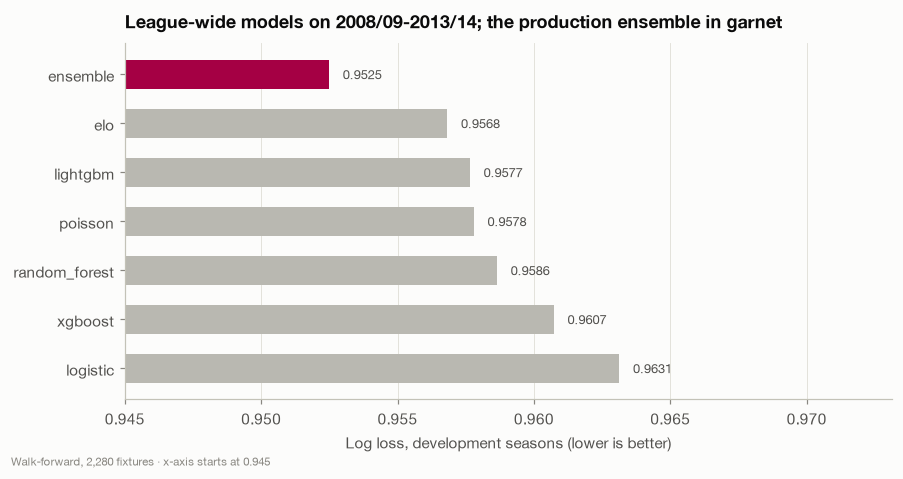

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.2))
order = dev.filter(pl.col("model") != "naive").sort("log_loss", descending=True)
names = order["model"].to_list() + ["ensemble"]
vals = order["log_loss"].to_list() + [backtest.score(ens)["log_loss"]]
colors = [style.NEUTRAL] * (len(names) - 1) + [style.BARCA]
ax.barh(names, vals, color=colors, height=0.6)
for i, v in enumerate(vals):
    ax.text(v + 0.0005, i, f"{v:.4f}", va="center", fontsize=8.5, color=style.INK_2)
ax.set_xlim(0.945, max(vals) + 0.01)
ax.set_xlabel("Log loss, development seasons (lower is better)")
ax.set_title("League-wide models on 2008/09-2013/14; the production ensemble in garnet")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
style.caption(ax, "Walk-forward, 2,280 fixtures · x-axis starts at 0.945")
style.savefig(fig, "13_model_comparison")
plt.show()

## The experiment log

Every run above is in MLflow. The runs of this notebook:

In [10]:
mlflow.set_tracking_uri(config.MLFLOW_URI)
log = mlflow.search_runs(experiment_names=[EXPERIMENT], order_by=["metrics.log_loss ASC"])
log[["tags.mlflow.runName", "params.n_features", "metrics.log_loss", "metrics.rps", "metrics.accuracy", "metrics.ece"]].head(15)

,tags.mlflow.runName,params.n_features,metrics.log_loss,metrics.rps,metrics.accuracy,metrics.ece
0,ensemble,90,0.952490,0.195764,0.551754,0.018712
1,elo,90,0.956824,0.196936,0.554386,0.021453
2,lightgbm,90,0.957654,0.196254,0.551754,0.020705
3,poisson,90,0.957795,0.197476,0.540789,0.026795
4,random_forest,90,0.958646,0.197357,0.555263,0.018811
5,xgboost,90,0.960729,0.197224,0.553509,0.019085
6,xgboost_tuned_2seasons,90,0.961044,0.197022,0.555263,0.019586
7,logistic,90,0.963130,0.198472,0.555263,0.024635
8,lightgbm_tuned_2seasons,90,0.965626,0.198133,0.546930,0.023280
9,lightgbm_tuned_1season,90,0.966893,0.198255,0.549561,0.028006


## Findings

1. **Tree ensembles reach the level of Elo and the Poisson model, but not
   beyond it on their own.** The signal is concentrated in team strength.
2. **Automated tuning overfits** at this sample size. Regularised defaults
   win or tie, and nested tuning keeps the comparison honest.
3. **Ensembles with LightGBM beat every single model.** The equal-weight
   ensemble of Elo, Poisson and LightGBM becomes the production model
   because it also yields the score distribution.
4. **All-league training beats Barcelona-only training**, and **event
   features add nothing** on top of the league ensemble for outcome
   prediction.

Next: the holdout evaluation, calibration and the comparison with the
betting market (`14_evaluation`).